# Opinión y percepción de consumidores — Punto 3

**Cliente:** EcoFood
**Pregunta del brief:** ¿qué valoran los consumidores, qué problemas aparecen y el precio es una barrera?
**Fuente:** reseñas públicas de Guía Óleo (`guiaoleo.com`)

## Qué tiene que responder este notebook

El brief pide tres cosas concretas:

1. **¿Qué valoran más los consumidores?**
2. **¿Qué problemas aparecen con frecuencia?**
3. **¿El precio es una barrera para adoptar productos sostenibles?**

Y una cuarta que no está escrita pero es la que hace que esto sirva: **¿esto coincide o contradice lo que dijo el punto 1?** El punto 1 describe la oferta instalada. Acá escuchamos a la demanda. Si las dos miradas no coinciden, eso es un hallazgo, no un error.

## Por qué este punto es distinto a los otros dos

El punto 1 usa un dataset abierto del GCBA: se descarga y listo. Acá no hay dataset: hay que **ir a buscar el dato a un sitio**. Eso obliga a resolver dos cosas antes de escribir una línea de código:

- **¿El sitio permite que lo lea un programa?** (`robots.txt` y términos de uso)
- **¿Qué hago si no lo permite?** (buscar otra fuente, no evadir el bloqueo)

Las dos se contestan en la sección 1. Si la respuesta fuera "no", este notebook no existiría.


## 1. Elección de la fuente y verificación de permiso

### Candidatos y por qué se descartaron

| Fuente | `robots.txt` | Términos de uso | Resultado |
|---|---|---|---|
| **Google Maps** | bloquea rutas de contenido | prohíbe extracción automatizada | descartado |
| **TripAdvisor** | `Disallow` sobre `/AllReviews`, `/api` y cientos de rutas | prohíbe scraping | descartado |
| **Guía Óleo** | `Allow: /` para `*`, bloquea solo `/admin/`, `/api/`, `/search?`, `/map?` | no prohíbe la lectura automatizada | **elegido** |

Guía Óleo es la guía gastronómica de referencia en Argentina y publica, en HTML, la reseña con su texto, la fecha, el puntaje de comida, servicio y ambiente, y el precio promedio por persona. Es exactamente el dato que pide el punto 3.

### La verificación, hecha en código

No alcanza con leer el `robots.txt` a mano una vez. Se verifica en el notebook, con la librería estándar, para que quede registrado qué se consultó y qué respondió.


In [1]:
from urllib.robotparser import RobotFileParser

import requests

AGENTE = 'ConsultingChallenge-EcoFood/1.0 (TP academico; datos publicos)'

# Se baja el robots.txt con el mismo agente que usa el scraper.
# Ojo: si se deja que RobotFileParser haga el request solo, usa el user-agent
# por defecto de Python y el sitio puede responder 403; ante un 403 el parser
# asume "todo prohibido". Por eso se baja aparte y se parsea el texto.
robots_txt = requests.get('https://guiaoleo.com/robots.txt',
                          headers={'User-Agent': AGENTE}, timeout=20).text

rp = RobotFileParser()
rp.parse(robots_txt.splitlines())

rutas = [
    '/',
    '/buenos-aires/mishiguene',
    '/buenos-aires/mishiguene/comunidad/676',
    '/api/',
    '/search?q=pizza',
]

for ruta in rutas:
    permitido = rp.can_fetch(AGENTE, 'https://guiaoleo.com' + ruta)
    print(f'{ruta:42s} {"PERMITIDO" if permitido else "BLOQUEADO"}')

print()
print('--- lineas relevantes del robots.txt ---')
for linea in robots_txt.splitlines():
    if linea.strip().startswith(('User-agent', 'Allow', 'Disallow')):
        print(linea)


/                                          PERMITIDO
/buenos-aires/mishiguene                   PERMITIDO
/buenos-aires/mishiguene/comunidad/676     PERMITIDO
/api/                                      BLOQUEADO
/search?q=pizza                            BLOQUEADO

--- lineas relevantes del robots.txt ---
User-agent: *
Allow: /
Disallow: /admin/
Disallow: /*/*/admin
Disallow: /api/
Disallow: /login
Disallow: /register
Disallow: /logout
Disallow: /password/
Disallow: /settings/
Disallow: /notifications
Disallow: /search?
Disallow: /map?
Disallow: /launch
Disallow: /offline.html


**Lectura:** las páginas públicas de restaurantes y de reseñas están permitidas. La API (`/api/`) está bloqueada y **no se usa**. Tampoco se usa el buscador ni el mapa, que también están bloqueados.

### Los términos de uso

Se revisó `https://guiaoleo.com/terms-of-service` buscando las palabras `scraping`, `automatizado`, `bot`, `crawler` y `extracción`. El documento **no prohíbe la lectura automatizada**. Lo que prohíbe es otra cosa:

- publicar contenido automatizado o spam;
- manipular calificaciones, rankings o visibilidad.

Este trabajo solo lee páginas públicas y no publica nada. Queda dentro de lo permitido.

### Protocolo de extracción

Aunque esté permitido, se aplican buenas prácticas para no golpear el servidor:

- **User-agent honesto.** El scraper se identifica como `ConsultingChallenge-EcoFood/1.0`. No simula ser un navegador.
- **Ritmo limitado.** Como máximo 3 pedidos en paralelo y una pausa entre pedidos (≈2 por segundo). El `robots.txt` no declara `Crawl-delay`, así que se elige un ritmo conservador igual.
- **Solo lo necesario.** Se piden las páginas de restaurantes del sitemap público y nada más.
- **Reanudable.** La salida es un JSONL que se escribe línea por línea: si se corta, se vuelve a correr y sigue donde quedó.
- **Con captura de respaldo.** Una corrida nueva solo reemplaza a la anterior si pasa la validación. Si falla, se sigue usando la última captura buena (sección 2).

El scraper completo está en `scripts/scrape_guiaoleo.py`. La celda siguiente muestra el corazón del parser: cómo se pasa de HTML a un registro con reseñas.


In [2]:
# El parser real vive en scripts/scrape_guiaoleo.py. Aca se reproduce la parte
# que importa: de una pagina de restaurante a un dict con sus resenas.
import json
import re

from bs4 import BeautifulSoup


def parsear_restaurante(html, url):
    soup = BeautifulSoup(html, 'lxml')

    # 1) datos estructurados: nombre, direccion, geo, rating agregado
    ld = {}
    m = re.search(r'type="application/ld\+json"[^>]*>(.*?)</script>', html, re.S)
    if m:
        ld = json.loads(m.group(1))

    # 2) resenas: cada tarjeta tiene un link a /comunidad/{id}
    resenas, vistos = [], set()
    for a in soup.select('a[href*="/comunidad/"]'):
        rid = a.get('href', '').split('#')[0].rsplit('/', 1)[-1]
        if not rid.isdigit() or rid in vistos:
            continue
        tarjeta = a.find_parent('div', class_=lambda c: c and 'rounded-2xl' in c)
        if tarjeta is None:
            continue
        vistos.add(rid)

        texto = next((d.get_text(' ', strip=True) for d in tarjeta.select('div.leading-relaxed')
                      if d.get_text(' ', strip=True) and not d.get_text(' ', strip=True).endswith('Continuar...')), '')

        sub, precio = {}, None
        for el in tarjeta.select('[title]'):
            titulo = el.get('title', '')
            if ':' in titulo and titulo.split(':')[0].strip() in ('Comida', 'Servicio', 'Ambiente'):
                dim, valor = titulo.split(':', 1)
                sub[dim.strip()] = valor.strip()
            elif titulo == 'Precio promedio por persona':
                precio = el.get_text(' ', strip=True)

        fecha = next((el.get_text(' ', strip=True) for el in tarjeta.select('a')
                      if el.get_text(' ', strip=True).lower().startswith('el ')), '')

        resenas.append({'review_id': rid, 'fecha': fecha, 'texto': texto,
                        'comida': sub.get('Comida'), 'servicio': sub.get('Servicio'),
                        'ambiente': sub.get('Ambiente'), 'precio': precio})

    addr = ld.get('address') or {}
    geo = ld.get('geo') or {}
    rating = ld.get('aggregateRating') or {}
    return {'url': url, 'nombre': ld.get('name'), 'barrio_fuente': addr.get('addressLocality'),
            'direccion': addr.get('streetAddress'), 'lat': geo.get('latitude'), 'lon': geo.get('longitude'),
            'rating': rating.get('ratingValue'), 'rating_count': rating.get('ratingCount'),
            'resenas': resenas}


print('parser definido: una pagina ->', 'nombre, direccion, geo, rating y lista de resenas')


parser definido: una pagina -> nombre, direccion, geo, rating y lista de resenas


### Demostración en vivo

Para que no quede en código muerto, se baja **una** página y se muestra qué devuelve el parser. Si el sitio no responde en el momento de correr el notebook, se avisa y se sigue con el JSONL ya guardado: el análisis no depende de esta celda.


In [3]:
import time

import requests

DEMO = 'https://guiaoleo.com/buenos-aires/mishiguene'

try:
    r = requests.get(DEMO, headers={'User-Agent': AGENTE, 'Accept-Language': 'es-AR,es;q=0.9'}, timeout=20)
    r.raise_for_status()
    demo = parsear_restaurante(r.text, DEMO)
    print('nombre: ', demo['nombre'])
    print('barrio: ', demo['barrio_fuente'])
    print('rating: ', demo['rating'], '/', demo['rating_count'], 'votos')
    print('resenas parseadas:', len(demo['resenas']))
    if demo['resenas']:
        primera = demo['resenas'][0]
        print()
        print('ejemplo de resena:')
        for k, v in primera.items():
            print(f'  {k:10s} {str(v)[:90]}')
except Exception as exc:
    print('no se pudo hacer la demo en vivo:', type(exc).__name__, exc)
    print('se sigue con el JSONL guardado en data/raw/')


nombre:  Mishiguene
barrio:  Palermo
rating:  25.2 / 9 votos
resenas parseadas: 5

ejemplo de resena:
  review_id  888
  fecha      El 27 abr 2026
  texto      
  comida     Muy bueno
  servicio   Excelente
  ambiente   Excelente
  precio     None


## 2. Qué se extrajo

El scrape recorre las **2.318 páginas de restaurantes de CABA** que figuran en el sitemap público. De cada una se guarda el registro del local y todas las reseñas visibles en la página.

La salida es `data/raw/guiaoleo_restaurantes.jsonl`, una línea por restaurante con sus reseñas anidadas. Es la **captura vigente**: el scraper solo la reemplaza cuando una corrida nueva pasa la validación (cobertura del sitemap, nombres parseados, cantidad de reseñas). Si una corrida falla (sin red, sitio caído, `robots.txt` que deja de permitir, rediseño que rompe el parser), este notebook sigue usando la **última captura buena**. `data/raw/guiaoleo_captura.json` registra de cuándo es y cómo terminó el último intento de actualizarla.

In [4]:
import json
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)

RAW = Path('../data/raw')
PROC = Path('../data/processed')

crudo = pd.DataFrame([json.loads(l) for l in (RAW / 'guiaoleo_restaurantes.jsonl').open(encoding='utf-8')])

# De cuándo es la captura y si el último intento de actualizarla falló.
ruta_meta = RAW / 'guiaoleo_captura.json'
meta = json.loads(ruta_meta.read_text(encoding='utf-8')) if ruta_meta.exists() else {}
vigente = meta.get('captura_vigente', {})
intento = meta.get('ultimo_intento', {})
print('captura vigente del:', vigente.get('fecha') or crudo['scraped_at'].max())
if intento and intento.get('resultado') != 'ok':
    print(f"OJO: el último intento de actualizar ({intento['fecha']}) terminó en '{intento['resultado']}': {intento['detalle']}")
    print('     se trabaja con la última captura buena.')
if 'de_captura_anterior' in crudo:
    print('locales completados con una captura anterior:', int(crudo['de_captura_anterior'].fillna(False).astype(bool).sum()))
print()

print('restaurantes scrapeados:', len(crudo))
print('columnas:', list(crudo.columns))
print('con error de descarga:', int(crudo.get('error', pd.Series(dtype=object)).notna().sum()))
print('con al menos una resena:', int(crudo['resenas'].map(lambda x: len(x) > 0).sum()))
print('resenas totales:', int(crudo['resenas'].map(len).sum()))

captura vigente del: 2026-11-16T21:26:33

restaurantes scrapeados: 2318
columnas: ['url', 'slug', 'nombre', 'barrio', 'direccion', 'lat', 'lon', 'rating', 'rating_count', 'resenas', 'scraped_at']
con error de descarga: 0
con al menos una resena: 861
resenas totales: 1075


### ¿Se bajó todo o solo una parte?

Cada página declara cuántas reseñas tiene el local (`rating_count`). Si el sitio mostrara solo las más recientes, habría muchos locales con más reseñas declaradas que bajadas. Se compara antes de declarar el límite.

In [5]:
declaradas = crudo['rating_count'].fillna(0).astype(int)
bajadas = crudo['resenas'].map(len)
print('reseñas declaradas por el sitio (suma):', int(declaradas.sum()))
print('reseñas bajadas:', int(bajadas.sum()), f'({bajadas.sum() / declaradas.sum() * 100:.1f}%)')
print('locales con más reseñas declaradas que bajadas:', int((declaradas > bajadas).sum()))
ids = sorted(int(r['review_id']) for lista in crudo['resenas'] for r in lista)
print('review_id va de', ids[0], 'a', ids[-1])

reseñas declaradas por el sitio (suma): 1087
reseñas bajadas: 1075 (98.9%)
locales con más reseñas declaradas que bajadas: 7
review_id va de 3 a 1360


**Lectura:** se bajó el 98,9% de las reseñas que el sitio declara para CABA; el tope de reseñas visibles por página solo recorta 7 locales. O sea: **no es una muestra de Guía Óleo, es prácticamente toda su comunidad en CABA**.

El límite real es otro: es una comunidad **chica y nueva**. Los `review_id` van de 3 a 1.360 para todo el sitio y todas las reseñas son del último año (ver el rango de fechas en la sección 3). Además, el scraper no logra identificar al autor de cada reseña, así que **no se puede saber cuántas personas distintas** escribieron: si unos pocos usuarios escriben mucho, sus gustos pesan de más.

## 3. Limpieza

Decisiones, en orden:

| Problema | Decisión |
|---|---|
| El restaurante está fuera de CABA (el sitemap de "buenos-aires" incluye direcciones de Vicente López y otros partidos) | Se asigna barrio por **punto en polígono** con los 48 barrios oficiales. Si el punto cae fuera, se descarta y se informa cuántos. |
| El barrio que declara Guía Óleo no es oficial (`Barrio Norte`, `Palermo Hollywood`, `Palermo Soho`) | No se usa: se recalcula desde lat/lon contra los polígonos oficiales. |
| Reseñas duplicadas (la misma aparece con y sin `#comments`) | Se deduplica por `slug + review_id`. |
| Precio como texto (`$60.000`) | Se convierte a número. `SIN DATO` si no hay. |
| Puntajes como texto (`Excelente`, `Muy bueno`...) | Se convierten a escala ordinal 0-3. |
| Fecha como texto (`El 12 abr 2026`) | Se convierte a fecha. |
| Reseña sin texto (solo puntajes) | Se conserva para el análisis de puntajes, se excluye del análisis de texto. |

**Nada se borra por ser extremo.** Un local con 40 reseñas y otro con 0 son parte del fenómeno, no ruido.


In [6]:
from datetime import datetime

ESCALA = {'Excelente': 3, 'Muy bueno': 2, 'Bueno': 1, 'Regular': 0}
MESES = {'ene': 1, 'feb': 2, 'mar': 3, 'abr': 4, 'may': 5, 'jun': 6,
         'jul': 7, 'ago': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dic': 12}


def precio_num(t):
    if not isinstance(t, str):
        return np.nan
    digitos = re.sub(r'[^\d]', '', t)
    return float(digitos) if digitos else np.nan


def fecha_de(t):
    m = re.match(r'El (\d{1,2}) (\w{3}) (\d{4})', str(t or ''))
    if not m:
        return pd.NaT
    dia, mes, anio = m.groups()
    return pd.Timestamp(int(anio), MESES.get(mes.lower(), 1), int(dia))


filas = []
for _, r in crudo.iterrows():
    if pd.notna(r.get('error')):
        continue
    for rev in (r['resenas'] or []):
        filas.append({
            'slug': r['slug'], 'nombre': r['nombre'], 'lat': r['lat'], 'lon': r['lon'],
            'rating_local': r['rating'], 'votos_local': r['rating_count'],
            'review_id': rev['review_id'], 'texto': rev['texto'], 'fecha': rev['fecha'],
            'comida': rev['comida'], 'servicio': rev['servicio'], 'ambiente': rev['ambiente'],
            'precio_txt': rev['precio'],
        })

resenas = pd.DataFrame(filas)
print('filas antes de deduplicar:', len(resenas))
resenas = resenas.drop_duplicates(['slug', 'review_id']).reset_index(drop=True)
print('filas despues:', len(resenas))

resenas['fecha'] = resenas['fecha'].map(fecha_de)
resenas['precio'] = resenas['precio_txt'].map(precio_num)
for dim in ['comida', 'servicio', 'ambiente']:
    resenas[dim] = resenas[dim].map(ESCALA)
resenas['texto'] = resenas['texto'].fillna('').str.strip()
resenas['tiene_texto'] = resenas['texto'].str.len() > 0
resenas['score'] = resenas[['comida', 'servicio', 'ambiente']].mean(axis=1)

print()
print('resenas:', len(resenas), '| con texto:', int(resenas['tiene_texto'].sum()))
print('con precio:', int(resenas['precio'].notna().sum()))
print('rango de fechas:', resenas['fecha'].min().date(), 'a', resenas['fecha'].max().date())
resenas.head(3)


filas antes de deduplicar: 1075
filas despues: 1075

resenas: 1075 | con texto: 948
con precio: 497
rango de fechas: 2025-12-02 a 2026-11-09


,slug,nombre,lat,lon,rating_local,votos_local,review_id,texto,fecha,comida,servicio,ambiente,precio_txt,precio,tiene_texto,score
0,san-carlos-pizzeria,San Carlos Pizzería,-34.61566170,-58.42988950,26.7,1.0,128,"Sin dudas, es la mejor pizzería de Caballito y...",2026-02-20,3,3,2,NaN,NaN,True,2.666667
1,panton-devoto,Panton devoto,-34.59845040,-58.51455560,26.7,1.0,534,Platos abundantes. Todo muy rico. Se puede ped...,2026-04-02,3,3,2,NaN,NaN,True,2.666667
2,biblos-palermo-bulnes,Biblos Palermo (BULNES),-34.58639430,-58.41034230,13.3,1.0,295,"Cafetería, pizzas, picadas, hamburguesas o rab...",2026-03-22,1,1,2,NaN,NaN,True,1.333333


### Asignación de barrio por geometría

Guía Óleo declara el barrio en `addressLocality`, pero usa nombres que no son los 48 oficiales: `Barrio Norte`, `Palermo Hollywood`, `Palermo Soho`, `Villa del Parque`. Usar ese campo obligaría a inventar equivalencias.

En cambio, cada restaurante trae latitud y longitud. Se lo ubica con **punto en polígono** contra `barrios_caba.geojson`. El barrio sale de la geometría oficial, no de una etiqueta comercial. Es el mismo criterio que usa cualquier mapa.


In [7]:
geo = json.loads((RAW / 'barrios_caba.geojson').read_text(encoding='utf-8'))


def anillos(geom):
    if geom['type'] == 'Polygon':
        return [geom['coordinates'][0]]
    return [p[0] for p in geom['coordinates']]


def dentro(x, y, anillo):
    """Ray casting: dice si el punto (x, y) cae dentro del anillo."""
    n, adentro, j = len(anillo), False, len(anillo) - 1
    for i in range(n):
        xi, yi = anillo[i][0], anillo[i][1]
        xj, yj = anillo[j][0], anillo[j][1]
        if ((yi > y) != (yj > y)) and (x < (xj - xi) * (y - yi) / (yj - yi) + xi):
            adentro = not adentro
        j = i
    return adentro


def barrio_comuna(lat, lon):
    for f in geo['features']:
        for anillo in anillos(f['geometry']):
            if dentro(lon, lat, anillo):
                return f['properties']['BARRIO'], int(float(f['properties']['COMUNA']))
    return None, None


def clave(texto):
    s = unicodedata.normalize('NFKD', str(texto)).encode('ascii', 'ignore').decode()
    return re.sub(r'[^a-z0-9]', '', s.lower())


oficiales = pd.read_csv(PROC / 'establecimientos_clean.csv')['barrio'].unique()
mapa_oficial = {clave(b): b for b in oficiales}

locales = crudo[crudo['error'].isna()].copy() if 'error' in crudo else crudo.copy()
locales[['barrio_geo', 'comuna']] = locales.apply(
    lambda r: pd.Series(barrio_comuna(float(r['lat']), float(r['lon']))), axis=1)
locales['barrio'] = locales['barrio_geo'].map(lambda b: mapa_oficial.get(clave(b), b))

ZONA = {1: 'Centro', 3: 'Centro', 2: 'Norte', 12: 'Norte', 13: 'Norte', 14: 'Norte',
        6: 'Oeste', 7: 'Oeste', 11: 'Oeste', 15: 'Oeste',
        4: 'Sur', 5: 'Sur', 8: 'Sur', 9: 'Sur', 10: 'Sur'}
locales['zona'] = locales['comuna'].map(ZONA)

fuera = locales[locales['barrio'].isna()]
print('restaurantes:', len(locales))
print('dentro de CABA:', int(locales['barrio'].notna().sum()))
print('fuera de CABA (descartados):', len(fuera))
print('barrios oficiales cubiertos:', locales['barrio'].nunique(), 'de 48')
print()
print(locales['zona'].value_counts().to_string())


restaurantes: 2318
dentro de CABA: 2235
fuera de CABA (descartados): 83
barrios oficiales cubiertos: 46 de 48

zona
Norte     1045
Oeste      596
Centro     412
Sur        182


In [8]:
# Se pega el barrio y la zona a cada resena
resenas = resenas.merge(
    locales[['slug', 'barrio', 'comuna', 'zona']], on='slug', how='inner'
)
print('resenas dentro de CABA:', len(resenas))
print('barrios con resenas:', resenas['barrio'].nunique())
print()
print(resenas.groupby('zona', observed=True).size().to_string())


resenas dentro de CABA: 1075
barrios con resenas: 42

zona
Centro    233
Norte     514
Oeste     215
Sur        90


In [9]:
# Se guarda la base limpia para que los otros puntos la puedan cruzar sin
# volver a correr el scrape.
salida = PROC / 'resenas_clean.csv'
resenas.to_csv(salida, index=False, encoding='utf-8')
print('guardado:', salida)
print('forma:', resenas.shape)


guardado: ../data/processed/resenas_clean.csv
forma: (1075, 19)


## 4. Distribuciones y outliers

Antes de sacar conclusiones hay que mirar la forma de los datos. Dos cosas importan acá:

- **Cuántas reseñas tiene cada local.** Si la mayoría tiene cero, cualquier promedio está hablando de una minoría que escribe reseñas, no del público general.
- **Cuántas reseñas tiene cada barrio.** Si la muestra se concentra en Palermo, el análisis "por barrio" es en realidad un análisis de Palermo con anécdotas del resto.

Los outliers **no se eliminan**: se identifican y se declara su peso. Un local con 40 reseñas es un dato, no un error.


In [10]:
por_local = resenas.groupby('slug').size()
print('locales con al menos una resena:', len(por_local))
print('resenas por local -> media:', round(por_local.mean(), 2), '| mediana:', por_local.median(), '| max:', por_local.max())
print()
q1, q3 = por_local.quantile([0.25, 0.75])
iqr = q3 - q1
print(f'Q1={q1:.0f}  Q3={q3:.0f}  IQR={iqr:.0f}')
print('OJO: el criterio clasico Q3 + 1.5*IQR degenera aca, porque la mayoria de los')
print('locales tiene 1 sola resena (Q1 = Q3 = 1) y el bigote cae en 1.0. No sirve.')
print()
# Criterio declarado en su lugar: dos cortes explicitos y conservadores.
p95 = por_local.quantile(0.95)
outliers_p95 = por_local[por_local >= p95].sort_values(ascending=False)
outliers_fijo = por_local[por_local >= 5].sort_values(ascending=False)
print(f'criterio A - P95 de la distribucion: {p95:.0f} resenas -> {len(outliers_p95)} locales')
print(f'criterio B - umbral fijo >= 5 resenas: {len(outliers_fijo)} locales')
print()
for nombre, serie in [('P95', outliers_p95), ('>= 5', outliers_fijo)]:
    print(f'{nombre:6s} peso en el total de resenas: {serie.sum() / por_local.sum() * 100:5.1f}%')
print()
print('locales con mas resenas (criterio >= 5):')
print(outliers_fijo.head(10).to_string())
print()
print('se conservan todos: los outliers se describen, no se eliminan.')


locales con al menos una resena: 861
resenas por local -> media: 1.25 | mediana: 1.0 | max: 5

Q1=1  Q3=1  IQR=0
OJO: el criterio clasico Q3 + 1.5*IQR degenera aca, porque la mayoria de los
locales tiene 1 sola resena (Q1 = Q3 = 1) y el bigote cae en 1.0. No sirve.

criterio A - P95 de la distribucion: 3 resenas -> 44 locales
criterio B - umbral fijo >= 5 resenas: 13 locales

P95    peso en el total de resenas:  15.3%
>= 5   peso en el total de resenas:   6.0%

locales con mas resenas (criterio >= 5):
slug
apia                        5
bacaro                      5
dandy-saavedra              5
doc-cafe-de-especialidad    5
don-zoilo                   5
el-ferroviario              5
gran-dabbang                5
heladeria-gruta             5
kansas-palermo              5
mishiguene                  5

se conservan todos: los outliers se describen, no se eliminan.


In [11]:
por_barrio = resenas.groupby('barrio').size().sort_values(ascending=False)
print('resenas por barrio -> media:', round(por_barrio.mean(), 1), '| mediana:', por_barrio.median())
print('barrios con >= 10 resenas:', int((por_barrio >= 10).sum()), 'de', len(por_barrio))
print('top 8 barrios por resenas:')
print(por_barrio.head(8).to_string())
print()
print('concentracion: top 5 barrios =', f'{por_barrio.head(5).sum() / por_barrio.sum() * 100:.1f}%', 'de las resenas')


resenas por barrio -> media: 25.0 | mediana: 7.5
barrios con >= 10 resenas: 20 de 42
top 8 barrios por resenas:
barrio
Palermo         169
Recoleta        158
San Nicolás     108
Belgrano         79
Caballito        59
Villa Crespo     52
Almagro          49
Villa Devoto     48

concentracion: top 5 barrios = 54.5% de las resenas


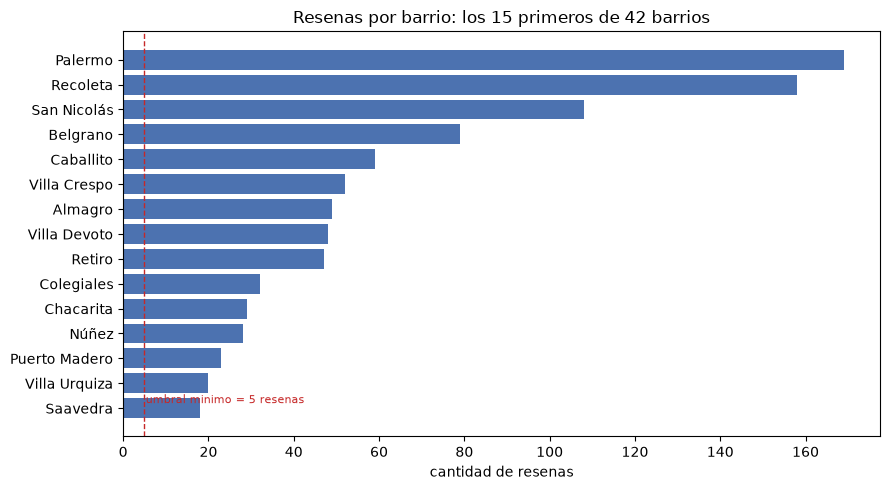

In [12]:
%matplotlib inline
import matplotlib.pyplot as plt

top = por_barrio.head(15)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index[::-1], top.values[::-1], color='#4C72B0')
ax.axvline(5, color='#C62828', linestyle='--', linewidth=1)
ax.text(5.3, 0.2, 'umbral minimo = 5 resenas', color='#C62828', fontsize=8)
ax.set_xlabel('cantidad de resenas')
ax.set_title('Resenas por barrio: los 15 primeros de %d barrios' % len(por_barrio))
plt.tight_layout()
plt.savefig('../images/05_resenas_por_barrio.png', dpi=150, bbox_inches='tight')
plt.show()


**Cómo se lee:** la distribución de reseñas por local es fuertemente asimétrica, como era esperable: la mayoría de los locales no tiene ninguna y unos pocos concentran varias. Eso obliga a dos precauciones:

1. Los promedios de puntaje describen a **quienes escriben reseñas**, un subconjunto chico y autoseleccionado. No son la opinión de todos los clientes.
2. El análisis por barrio se hace con umbral mínimo de reseñas. Los barrios con pocas se informan como no concluyentes, igual que en el punto 1.


## 5. Qué valoran los consumidores

Cada reseña trae tres puntajes separados: **comida**, **servicio** y **ambiente**. Eso permite contestar la pregunta sin interpretar texto: alcanza con ver qué dimensión se lleva los "Excelente" y cuál se queda con los "Bueno" y "Regular".

Escala: `Excelente`=3, `Muy bueno`=2, `Bueno`=1, `Regular`=0.


In [13]:
dimensiones = ['comida', 'servicio', 'ambiente']

tabla_dim = pd.DataFrame({
    'n': [resenas[d].notna().sum() for d in dimensiones],
    'media_0_3': [resenas[d].mean() for d in dimensiones],
    'pct_excelente': [(resenas[d].dropna() == 3).mean() * 100 for d in dimensiones],
    'pct_bueno_o_menos': [(resenas[d].dropna() <= 1).mean() * 100 for d in dimensiones],
}, index=dimensiones).round(2)

tabla_dim


,n,media_0_3,pct_excelente,pct_bueno_o_menos
comida,1075,2.35,48.28,11.53
servicio,1075,2.21,41.58,17.95
ambiente,1075,2.20,37.21,15.72


In [14]:
print('=== Puntaje medio por dimension (0 a 3) ===')
for d in dimensiones:
    v = resenas[d].dropna()
    print(f'  {d:10s} {v.mean():.2f}   excelente {(v == 3).mean() * 100:.1f}%   bueno o menos {(v <= 1).mean() * 100:.1f}%')
print()
peor = tabla_dim['media_0_3'].idxmin()
mejor = tabla_dim['media_0_3'].idxmax()
print(f'dimension mejor valorada: {mejor} ({tabla_dim.loc[mejor, "media_0_3"]:.2f})')
print(f'dimension peor valorada:  {peor} ({tabla_dim.loc[peor, "media_0_3"]:.2f})')
print()
print('brecha comida - ambiente:', round(tabla_dim.loc['comida', 'media_0_3'] - tabla_dim.loc['ambiente', 'media_0_3'], 2))


=== Puntaje medio por dimension (0 a 3) ===
  comida     2.35   excelente 48.3%   bueno o menos 11.5%
  servicio   2.21   excelente 41.6%   bueno o menos 18.0%
  ambiente   2.20   excelente 37.2%   bueno o menos 15.7%

dimension mejor valorada: comida (2.35)
dimension peor valorada:  ambiente (2.20)

brecha comida - ambiente: 0.15


**Lo que dice:** la comida se despega del resto (2,35 sobre 3) y es la que más "Excelente" se lleva (48%). Servicio y ambiente quedan casi empatados por debajo (2,21 y 2,20), pero con perfiles distintos: el servicio concentra más evaluaciones malas (18% de "Bueno" o menos, contra 11,5% en comida), mientras el ambiente se queda en "Muy bueno" y rara vez baja de ahí.

Para EcoFood eso tiene una implicación directa: **el producto no es el problema, el contexto sí**. Un local saludable compite con la experiencia completa, no solo con el plato.

**Explicación alternativa que hay que descartar:** podría ser un efecto de techo, es decir, que la gente puntúe "Excelente" la comida por defecto y sea más dura con el resto. Se chequea abajo: si la distribución de comida tuviera casi todo en 3 y la de servicio estuviera repartida, el hallazgo sería un artefacto de la escala, no una preferencia.


In [15]:
dist = pd.DataFrame({
    'Excelente': [(resenas[d].dropna() == 3).mean() * 100 for d in dimensiones],
    'Muy bueno': [(resenas[d].dropna() == 2).mean() * 100 for d in dimensiones],
    'Bueno': [(resenas[d].dropna() == 1).mean() * 100 for d in dimensiones],
    'Regular': [(resenas[d].dropna() == 0).mean() * 100 for d in dimensiones],
}, index=dimensiones).round(1)
dist


,Excelente,Muy bueno,Bueno,Regular
comida,48.3,40.2,10.0,1.5
servicio,41.6,40.5,15.5,2.4
ambiente,37.2,47.1,14.4,1.3


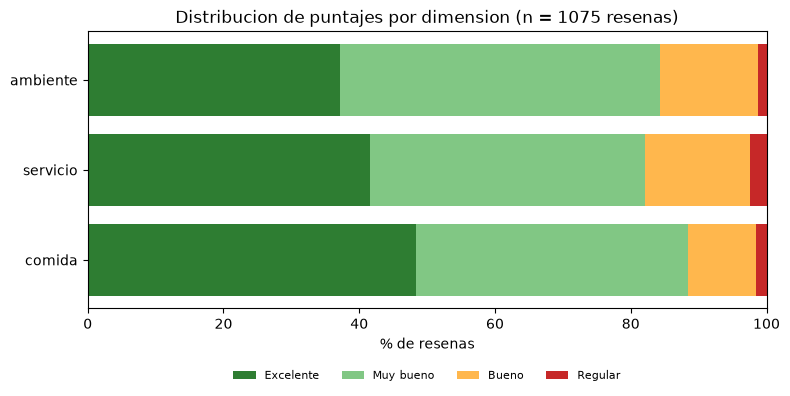

In [16]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.2))
colores_dim = {'Excelente': '#2E7D32', 'Muy bueno': '#81C784', 'Bueno': '#FFB74D', 'Regular': '#C62828'}
izq = np.zeros(len(dimensiones))
for nivel in ['Excelente', 'Muy bueno', 'Bueno', 'Regular']:
    ax.barh(dimensiones, dist[nivel], left=izq, color=colores_dim[nivel], label=nivel)
    izq += dist[nivel].values
ax.set_xlabel('% de resenas')
ax.set_title('Distribucion de puntajes por dimension (n = %d resenas)' % len(resenas))
ax.legend(ncol=4, fontsize=8, loc='lower center', bbox_to_anchor=(0.5, -0.3), frameon=False)
ax.set_xlim(0, 100)
plt.tight_layout()
plt.savefig('../images/04_dimensiones_puntaje.png', dpi=150, bbox_inches='tight')
plt.show()


Si la distribución de comida estuviera aplastada contra "Excelente" y la de ambiente no, el efecto techo sería la explicación y el hallazgo se caería. Lo que se ve es que **las tres dimensiones usan toda la escala**; la diferencia está en el centro de la distribución, no en un techo. El hallazgo se sostiene.

## 6. Qué problemas aparecen con frecuencia

Ahora sí, texto. Se normaliza (minúsculas, sin tildes) y se buscan familias de palabras. No es un modelo de lenguaje: es un diccionario explícito, y por eso se puede auditar.

| Tema | Qué busca |
|---|---|
| `precio` | precio, caro/a, carísimo, barato, económico, costoso |
| `atencion` | atención, mozo/a, servicio, amable, grosero, trato |
| `espera` | espera, demora, tardó, lento, fila |
| `rapidez` | rápido/a, rapidez, ágil |
| `ambiente` | ambiente, ruido, música, decoración, mesa |
| `comida` | rico, sabor, frío, crudo, porción, quemado |
| `higiene` | baño, sucio, limpio, higiene |
| `reserva` | reserva, turno, disponibilidad |
| `saludable` | vegano, vegetariano, saludable, orgánico, natural, sin gluten, gluten free, sin TACC, celíaco, integral |

**El diccionario se ajustó leyendo el contexto de cada palabra dudosa**, porque una palabra mal elegida fabrica un hallazgo:

- `cuenta` salió de `precio`: casi siempre es "tener en cuenta" o "cuenta con". `valor` y `plata` también salieron ("tiene otro valor", "La Plata").
- `cara` queda en `precio`, pero antes se borra la frase "lavada de cara".
- `rápido` salió de `espera` y pasó a su propio tema: casi siempre es un elogio ("atención rápida"). Mezclado con "demora", inflaba el tema espera.
- `onda` salió de `atencion`: casi siempre describe el lugar, no al personal.
- En `saludable` se borran "iluminación natural" y "luz natural" antes de buscar.

In [17]:
def normalizar(t):
    s = unicodedata.normalize('NFKD', str(t)).encode('ascii', 'ignore').decode()
    return re.sub(r'\s+', ' ', s.lower()).strip()


TEMAS = {
    'precio': r'\b(?:precio|precios|caro|caros|cara|caras|carisim\w*|costoso|costosa|barato|barata|economico|economica)\b',
    'atencion': r'\b(?:atencion|mozo|mozos|moza|mozas|camarero|servicio|amable|grosero|grosera|trato)\b',
    'espera': r'\b(?:espera|esperamos|esperar|demora|demor\w*|tardo|tardan|lento|lenta|fila)\b',
    'rapidez': r'\b(?:rapido|rapida|rapidez|agil)\b',
    'ambiente': r'\b(?:ambiente|ruido|ruidoso|ruidosa|musica|decoracion|decorado|lindo|linda|comodo|comoda|incomodo|incomoda|mesa|mesas)\b',
    'comida': r'\b(?:rico|rica|ricos|ricas|riquisi\w*|sabor|sabroso|frio|fria|crudo|cruda|insipido|insipida|porcion|porciones|abundante|escaso|escasa|quemado|seco|seca|milanesa|pizza|plato|platos)\b',
    'higiene': r'\b(?:banio|bano|sucio|sucia|limpio|limpia|higiene)\b',
    'reserva': r'\b(?:reserva|reservamos|reservar|turno|disponibilidad)\b',
    'saludable': r'\b(?:vegano|vegana|veganos|veganas|vegetariano|vegetariana|vegetarianos|saludable|saludables|organico|organica|natural|sin gluten|gluten free|sin tacc|sintacc|celiaco|celiaca|celiacos|celiacas|integral)\b',
}

# Frases que se borran antes de buscar el tema, porque usan la palabra con otro sentido.
EXCLUSIONES = {
    'precio': r'lavada de cara',
    'saludable': r'(?:iluminacion|luz) natural',
}


def marcar(textos, tema):
    base = textos.str.replace(EXCLUSIONES[tema], ' ', regex=True) if tema in EXCLUSIONES else textos
    return base.str.contains(TEMAS[tema], regex=True)


con_texto = resenas[resenas['tiene_texto']].copy()
con_texto['texto_norm'] = con_texto['texto'].map(normalizar)

for tema in TEMAS:
    # prefijo t_ para no pisar la columna 'comida', 'ambiente' ni 'precio'
    con_texto['t_' + tema] = marcar(con_texto['texto_norm'], tema)

print('resenas con texto:', len(con_texto))
print()
columnas_tema = ['t_' + t for t in TEMAS]
menciones = con_texto[columnas_tema].sum().sort_values(ascending=False)
menciones.index = [c.replace('t_', '') for c in menciones.index]
print('menciones por tema (una resena puede tocar varios):')
print(menciones.to_string())

resenas con texto: 948

menciones por tema (una resena puede tocar varios):
comida       454
ambiente     358
atencion     315
precio       173
espera        60
rapidez       46
saludable     39
reserva       22
higiene       12


### Positivas contra negativas

La frecuencia sola no dice nada: "precio" puede aparecer tanto en "buen precio" como en "carísimo". Lo que importa es **en qué tipo de reseña aparece cada tema**. Para eso hace falta una medida de sentimiento.

Se usa un **léxico** explícito de palabras positivas y negativas (no un modelo entrenado), y se valida contra los puntajes: si el léxico funciona, las reseñas con puntaje bajo deben dar polaridad negativa. Si no correlacionan, el léxico se descarta.


In [18]:
POS = set('''rico rica ricos ricas riquisimo riquisima bueno buena excelente espectacular increible
delicioso deliciosa recomendable recomendado perfecto perfecta genial hermoso hermosa lindo linda
amable atento atenta abundante fresco fresca sabroso impecable mejor encanto gusto volveria vale'''.split())

NEG = set('''malo mala feo fea horrible terrible pesimo pesima caro cara carisimo carisima frio fria
crudo cruda insipido insipida desagradable sucio sucia grosero grosera lento lenta demora decepcion
decepcionante error faltaba olvidaron quemado seco seca escaso escasa ruidoso ruidosa incomodo incomoda nunca'''.split())


def polaridad(t, excluir=None):
    """(positivas - negativas) / (total + 1). Con `excluir` (un patrón), esas palabras no cuentan."""
    palabras = re.findall(r'[a-z]+', normalizar(t))
    if excluir:
        palabras = [p for p in palabras if not re.fullmatch(excluir, p)]
    pos = sum(p in POS for p in palabras)
    neg = sum(p in NEG for p in palabras)
    return (pos - neg) / (pos + neg + 1)


def sentimiento(pol):
    return np.where(pol > 0.15, 'positiva', np.where(pol < -0.15, 'negativa', 'neutra'))


con_texto['polaridad'] = con_texto['texto'].map(polaridad)
con_texto['sentimiento'] = sentimiento(con_texto['polaridad'])

print('distribucion del sentimiento:')
print(con_texto['sentimiento'].value_counts().to_string())
print()
print('polaridad media segun puntaje de comida (validacion del lexico):')
print(con_texto.groupby('comida')['polaridad'].agg(['mean', 'size']).round(3).to_string())

distribucion del sentimiento:
sentimiento
positiva    654
neutra      252
negativa     42

polaridad media segun puntaje de comida (validacion del lexico):
         mean  size
comida             
0      -0.041    16
1       0.189    98
2       0.369   377
3       0.451   457


**Validación del léxico:** la polaridad media sube con el puntaje de comida. La relación no es perfecta (es un léxico, no un modelo), pero va en la dirección correcta. Alcanza para usar el sentimiento como señal gruesa, no para afirmar el sentimiento exacto de una reseña.

**Pero el léxico tiene dos problemas para este caso:**

1. Clasifica como "negativas" muy pocas reseñas (la mayoría de las reseñas de Guía Óleo son positivas y el léxico es conservador). Con tan pocas negativas, comparar temas "en negativas" es frágil.
2. **Es circular si se lo cruza con los temas.** El léxico negativo incluye `caro`, `lento` y `demora`, y el positivo `amable` y `rico`. Una reseña que dice "caro" ya es negativa por construcción, y después "se descubre" que el precio aparece en las negativas. Por eso, cuando se cruza un tema con el sentimiento, la polaridad se recalcula **sin las palabras de ese tema**.

Por eso el corte principal **no usa el léxico**: usa el puntaje que puso el propio usuario, que no depende del texto. Se comparan las reseñas con puntaje bajo (promedio ≤ 2) contra las de puntaje alto (promedio ≥ 2,67).

**Ojo con el nombre "bajo":** promedio ≤ 2 incluye a quien puso "Muy bueno" en las tres dimensiones. No son reseñas malas: son reseñas que no llegan al "Excelente". Para ver si el resultado depende de ese corte, se arma también un grupo **bajo estricto** (promedio ≤ 1,67: al menos una dimensión en "Bueno" o menos).

In [19]:
con_texto['grupo'] = np.where(con_texto['score'] <= 2, 'bajo',
                       np.where(con_texto['score'] >= 2.67, 'alto', 'medio'))
con_texto['grupo_estricto'] = np.where(con_texto['score'] <= 1.67, 'bajo estricto',
                                np.where(con_texto['score'] >= 2.67, 'alto', 'resto'))

print(con_texto['grupo'].value_counts().to_string())
print()
print('dentro de "bajo", reseñas con "Muy bueno" en las tres dimensiones:',
      int((con_texto['grupo'].eq('bajo') & con_texto['score'].round(2).eq(2)).sum()))
print('bajo estricto (promedio <= 1,67):', int((con_texto['grupo_estricto'] == 'bajo estricto').sum()))
print()
print('puntaje promedio por grupo:')
print(con_texto.groupby('grupo')['score'].agg(['mean', 'size']).round(2).to_string())

grupo
bajo     419
medio    281
alto     248

dentro de "bajo", reseñas con "Muy bueno" en las tres dimensiones: 199
bajo estricto (promedio <= 1,67): 220

puntaje promedio por grupo:
       mean  size
grupo            
alto   3.00   248
bajo   1.66   419
medio  2.48   281


In [20]:
from math import erf, sqrt


def p_dos_proporciones(a, b):
    """Test z de dos proporciones, dos colas. `a` y `b` son series booleanas."""
    na, nb = len(a), len(b)
    p = (a.sum() + b.sum()) / (na + nb)
    se = sqrt(p * (1 - p) * (1 / na + 1 / nb))
    if se == 0:
        return 1.0
    z = (a.mean() - b.mean()) / se
    return 2 * (1 - 0.5 * (1 + erf(abs(z) / sqrt(2))))


bajo = con_texto[con_texto['grupo'] == 'bajo']
alto = con_texto[con_texto['grupo'] == 'alto']
bajo_e = con_texto[con_texto['grupo_estricto'] == 'bajo estricto']

filas = []
for tema in TEMAS:
    col = 't_' + tema
    filas.append({
        'tema': tema,
        'bajo': bajo[col].mean() * 100,
        'alto': alto[col].mean() * 100,
        'brecha': (bajo[col].mean() - alto[col].mean()) * 100,
        'p': p_dos_proporciones(bajo[col], alto[col]),
        'bajo_estricto': bajo_e[col].mean() * 100,
        'p_estricto': p_dos_proporciones(bajo_e[col], alto[col]),
    })
tabla_temas = pd.DataFrame(filas).set_index('tema')
print(f'n bajo = {len(bajo)} | n bajo estricto = {len(bajo_e)} | n alto = {len(alto)}')
tabla_temas.round({'bajo': 1, 'alto': 1, 'brecha': 1, 'p': 4, 'bajo_estricto': 1, 'p_estricto': 4}) \
    .sort_values('brecha', ascending=False)

n bajo = 419 | n bajo estricto = 220 | n alto = 248


,bajo,alto,brecha,p,bajo_estricto,p_estricto
tema,,,,,,
espera,8.1,2.4,5.7,0.0028,13.2,0.0000
rapidez,6.2,2.8,3.4,0.0515,6.4,0.0648
precio,18.4,15.7,2.7,0.3826,19.5,0.2780
ambiente,37.9,35.9,2.1,0.5946,39.1,0.4746
saludable,4.8,3.6,1.1,0.4837,3.6,0.9966
higiene,1.7,1.2,0.5,0.6359,2.7,0.2328
comida,48.9,48.8,0.1,0.9730,45.0,0.4122
reserva,0.7,3.2,-2.5,0.0139,0.5,0.0293
atencion,29.8,41.9,-12.1,0.0015,31.4,0.0180


In [21]:
# Segunda mirada, con el léxico pero SIN circularidad: para cada tema, la polaridad
# se recalcula sacando las palabras de ese tema.
filas = []
for tema in TEMAS:
    col = 't_' + tema
    sent = pd.Series(sentimiento(con_texto['texto'].map(lambda t: polaridad(t, TEMAS[tema]))),
                     index=con_texto.index)
    pos, neg = con_texto[sent == 'positiva'], con_texto[sent == 'negativa']
    filas.append({'tema': tema, 'positivas': pos[col].mean() * 100, 'negativas': neg[col].mean() * 100,
                  'n_negativas': len(neg), 'p': p_dos_proporciones(neg[col], pos[col])})
tabla_lexico = pd.DataFrame(filas).set_index('tema')
tabla_lexico['brecha'] = tabla_lexico['negativas'] - tabla_lexico['positivas']
tabla_lexico.round({'positivas': 1, 'negativas': 1, 'brecha': 1, 'p': 4}).sort_values('brecha', ascending=False)

,positivas,negativas,n_negativas,p,brecha
tema,,,,,
espera,5.9,13.2,38,0.0738,7.2
comida,48.3,53.3,45,0.5180,5.0
higiene,1.5,2.4,41,0.6485,0.9
precio,18.6,18.8,32,0.9807,0.2
saludable,4.6,4.8,42,0.9582,0.2
atencion,38.0,38.1,42,0.9924,0.1
reserva,2.3,2.4,42,0.9708,0.1
rapidez,5.5,2.4,42,0.3818,-3.1
ambiente,41.0,35.9,39,0.5265,-5.1


**Cómo se lee:** un tema con `brecha` grande y positiva es un tema que aparece **cuando la experiencia se evalúa peor**. Un tema con brecha cercana a cero se menciona siempre, bien o mal, y por eso no sirve para explicar el descontento.

La columna `p` es un test de dos proporciones: dice qué tan probable es ver esa diferencia solo por azar. Como se comparan 9 temas a la vez, la vara es más exigente que el 0,05 de siempre: se pide **p < 0,005** (0,05 / 9) para llamar "firme" a una diferencia.

**Explicación alternativa que hay que descartar:** la diferencia podría venir de que las reseñas bajas son más largas y, al tener más texto, mencionan más temas. Se controla mirando el largo promedio de cada grupo; si son parecidos, la diferencia es de contenido, no de extensión.

In [22]:
largo = con_texto.assign(palabras=con_texto['texto_norm'].str.split().str.len())
print('largo promedio por grupo (palabras):')
print(largo.groupby('grupo')['palabras'].agg(['mean', 'median', 'size']).round(1).to_string())


largo promedio por grupo (palabras):
       mean  median  size
grupo                    
alto   44.5    29.5   248
bajo   47.1    39.0   419
medio  46.8    39.0   281


In [23]:
# El diccionario puede subestimar el tema 'saludable': la gente no siempre usa
# la palabra 'saludable'. Se prueba un lexico ampliado para ver cuánto cambia.
AMPLIADO = (r'\b(?:liviano|liviana|fresco|fresca|sin culpa|plant based|plant-based|'
            r'proteico|proteica|proteina|veggie|vegetal|verduras|ensalada|ensaladas|'
            r'integrales|keto|detox|light|apto celiaco|sin conservantes|'
            r'agroecologico|agroecologica|de estacion)\b')

menciones_ampliadas = con_texto['t_saludable'] | con_texto['texto_norm'].str.contains(AMPLIADO, regex=True)
print('menciones de lo saludable, lexico original:', int(con_texto['t_saludable'].sum()),
      f'({con_texto["t_saludable"].mean() * 100:.1f}%)')
print('menciones de lo saludable, lexico ampliado:', int(menciones_ampliadas.sum()),
      f'({menciones_ampliadas.mean() * 100:.1f}%)')
print()
print('Un porcentaje solo dice algo contra una vara: ver la sección siguiente.')

menciones de lo saludable, lexico original: 39 (4.1%)
menciones de lo saludable, lexico ampliado: 87 (9.2%)

Un porcentaje solo dice algo contra una vara: ver la sección siguiente.


### ¿Poco comparado con qué?

Un porcentaje bajo de menciones parece decir "lo saludable no interesa", pero solo dice algo **contra una vara**. Guía Óleo reseña restaurantes de todo tipo, no locales saludables: es esperable que pocas reseñas hablen del tema. La vara es **cuánta oferta saludable hay**, y el punto 1 la mide.

También importa **de qué se habla** cuando se habla de lo saludable.

In [24]:
locales_p1 = pd.read_csv(PROC / 'establecimientos_clean.csv')
print('vara (punto 1): oferta saludable estricta', f"{locales_p1['es_saludable_estricto'].mean() * 100:.1f}%",
      '| amplia', f"{locales_p1['es_saludable_amplio'].mean() * 100:.2f}%")
print('reseñas que mencionan lo saludable:', f"{con_texto['t_saludable'].mean() * 100:.1f}%",
      f"({int(con_texto['t_saludable'].sum())} de {len(con_texto)})")
print()

SUBTEMAS = {
    'celíacos / sin gluten / sin TACC': r'\b(?:sin gluten|gluten free|sin tacc|sintacc|celiac\w*)\b',
    'vegano / vegetariano': r'\b(?:vegan\w*|vegetarian\w*)\b',
    'saludable / natural / integral / orgánico': r'\b(?:saludable\w*|natural|integral|organic\w*)\b',
}
texto_sal = con_texto.loc[con_texto['t_saludable'], 'texto_norm'].str.replace(EXCLUSIONES['saludable'], ' ', regex=True)
print('de qué se habla dentro de esas menciones (una reseña puede tocar varios):')
for nombre, patron in SUBTEMAS.items():
    print(f'  {nombre:45s} {int(texto_sal.str.contains(patron, regex=True).sum())}')

vara (punto 1): oferta saludable estricta 0.4% | amplia 2.85%
reseñas que mencionan lo saludable: 4.1% (39 de 948)

de qué se habla dentro de esas menciones (una reseña puede tocar varios):
  celíacos / sin gluten / sin TACC              20
  vegano / vegetariano                          8
  saludable / natural / integral / orgánico     12


### La pista sin TACC, contra las otras fuentes

El subgrupo más grande es el de celíacos. Antes de leerlo como señal se miran tres cosas: qué dicen esas reseñas, si hay oferta especializada (en Guía Óleo y en el punto 1) y si aparece en la búsqueda (punto 2, Google Trends).

In [25]:
PATRON_TACC = r'\b(?:sin gluten|gluten free|sin tacc|sintacc|celiac\w*)\b'
celiacas = con_texto[con_texto['texto_norm'].str.contains(PATRON_TACC, regex=True)]
resto = con_texto.drop(celiacas.index)
print('reseñas que hablan de celiaquía / sin TACC:', len(celiacas))
print('puntaje medio:', round(celiacas['score'].mean(), 2), '| resto de las reseñas:', round(resto['score'].mean(), 2))
# ¿Hablan de escasez? Palabras que indican que conseguir la opción es difícil.
ESCASEZ = r'\b(?:pocos|pocas|unicos|unicas|unico|unica|oasis|salvador\w*|refugio\w*|no se consigue|dificil|cuesta encontrar)\b'
habla_escasez = celiacas['texto_norm'].str.contains(ESCASEZ, regex=True)
print('de esas, con lenguaje de escasez:', int(habla_escasez.sum()))
para_llevar = celiacas['texto_norm'].str.contains(r'\b(?:almacen|para llevar|panaderia|panificados|budines|delivery|productos)\b', regex=True)
print('de esas, que hablan de productos / para llevar / panadería:', int(para_llevar.sum()))
print()
print('fragmentos con lenguaje de escasez (recortados alrededor de la mención):')
for t in celiacas.loc[habla_escasez, 'texto']:
    m = re.search(r'(?i)(sin gluten|sin tacc|cel[ií]ac\w*|gluten free)', t)
    i = m.start() if m else 0
    print('  ...' + t[max(0, i - 60): i + 70].replace('\n', ' ') + '...')

# Oferta especializada: locales de Guía Óleo dentro de CABA cuyo nombre lo dice.
dentro = locales[locales['barrio'].notna()]
nombre_tacc = dentro['nombre'].fillna('').map(normalizar).str.contains(r'gluten|tacc|celiac|celimuzza', regex=True)
print()
print('locales de Guía Óleo en CABA con "gluten free / sin TACC" en el nombre:',
      int(nombre_tacc.sum()), 'de', len(dentro), f'({nombre_tacc.mean() * 100:.1f}%)')
print('  por barrio:', dentro.loc[nombre_tacc, 'barrio'].value_counts().to_dict())
print('categorías del GCBA (punto 1) que identifiquen sin TACC:',
      [c for c in locales_p1['cocina'].unique() if re.search('CELIA|TACC|GLUTEN', str(c))] or 'ninguna')

# Búsqueda (punto 2): interés en Google Trends, escala común entre los cinco términos.
ruta_trends = RAW / 'trends_juntos.csv'
if ruta_trends.exists():
    trends = pd.read_csv(ruta_trends)
    print()
    print(f'Google Trends (punto 2), Argentina, {len(trends)} semanas, interés medio en escala común:')
    print(trends.mean().round(1).sort_values(ascending=False).to_string())
else:
    print('trends_juntos.csv no está: falta integrar el punto 2')

reseñas que hablan de celiaquía / sin TACC: 20
puntaje medio: 2.17 | resto de las reseñas: 2.25
de esas, con lenguaje de escasez: 6
de esas, que hablan de productos / para llevar / panadería: 6

fragmentos con lenguaje de escasez (recortados alrededor de la mención):
  ...Fuimos a almorzar con mis dos hijas (una de ellas celíaca). La propuesta es muy interesante para brunch, desayuno y meri...
  ...e amigos es de esos pocos refugios que tenemos las familias celíacas para comer rico, abundante y libres de cualquier peligro. El ...
  ...Un oasis para la comida sin gluten. Resulta difícil transmitir, siendo celíacos, lo difícil qu...
  ...ir delivery y es una herramienta salvadora para una familia celíaca como nosotros. La pizza a veces puede sentirse un poco seca, p...
  ...tta, Baguettes, Bagel de Salmón... que tentación. Menu apto Celiacos algo muy importante y no se consigue en todos lados. Bebidas ...
  ...Uno de los únicos lugares que reúnen cocina 100% gluten free y vegana La carac

**Lectura:** fuentes distintas apuntan al mismo lugar.

| Fuente | Qué dice sobre sin TACC |
|---|---|
| Búsqueda (punto 2) | Es por lejos el término con más interés: 73,5 de media contra 3,9 de "alimentación saludable" y menos de 2 del resto, en escala común. |
| Reseñas (punto 3) | Es el subtema saludable más mencionado (20 de las 39 reseñas que tocan lo saludable). 6 de esas 20 usan lenguaje de escasez ("de esos pocos refugios", "un oasis", "no se consigue en todos lados") y 6 hablan de productos, panadería, almacén o para llevar. |
| Oferta (Guía Óleo) | Hay oferta especializada, pero mínima: 13 de 2.235 locales (0,6%) lo dicen en el nombre, repartidos en 9 barrios. |
| Oferta (punto 1, GCBA) | El registro de Turismo **no tiene una categoría** que la identifique. El "cero" del punto 1 es un hueco de clasificación, no ausencia de mercado. |

**Explicaciones alternativas:**

- *"sin TACC" se busca más porque es el rótulo oficial de los envases, no porque haya más interés.* **No se descarta del todo:** se compara un rótulo concreto con conceptos vagos. Pero eso refuerza la lectura de producto: es la palabra con la que la gente busca qué comprar.
- *Son pocas reseñas (20) y podrían ser de pocas personas.* **No se puede descartar:** el scraper no identifica autores. Es una pista fuerte para validar, no una medición del tamaño del mercado.
- *Es un grupo de quejas.* **Descartada:** el puntaje medio de esas reseñas (2,17) es casi igual al del resto (2,25).

Es el cruce que pide el bonus del caso: **alta búsqueda, oferta especializada mínima y consumidores que dicen que cuesta encontrarla.** Y apunta a producto (panificados, almacén, para llevar), que es lo que EcoFood quiere vender.

## 7. ¿El precio es una barrera?

Tres cortes distintos, porque una sola tabla no alcanza:

1. **Precio declarado contra puntaje.** Si los locales caros puntúan igual o mejor, el precio no es una barrera de satisfacción.
2. **Menciones de precio según sentimiento.** Si "precio" aparece mucho más en negativas que en positivas, el precio duele.
3. **Precio contra lo que la gente esperaba.** El puntaje de comida no cambia con el precio; el de ambiente sí. Eso separa "caro para lo que es" de "caro y bueno".


In [26]:
con_precio = resenas[resenas['precio'].notna()].copy()

# Hay valores que no son precios: '$20', '$40', '$50', '$80'. Son artefactos de
# carga (alguien escribio el precio en miles, o directamente cualquier cosa).
# Se declara un piso de $1.000 por persona y se informa cuanto se descarta.
invalidos = con_precio[con_precio['precio'] < 1000]
print('resenas con precio declarado (crudo):', len(con_precio))
print('valores descartados por debajo de $1.000:', len(invalidos), '->', sorted(invalidos['precio_txt'].unique()))
con_precio = con_precio[con_precio['precio'] >= 1000].copy()
print('resenas con precio valido:', len(con_precio), f'({len(con_precio) / len(resenas) * 100:.0f}% del total)')
print()

con_precio['precio_miles'] = (con_precio['precio'] / 1000).round(0)
print('precio mediano:', int(con_precio['precio'].median()), '| minimo:', int(con_precio['precio'].min()), '| maximo:', int(con_precio['precio'].max()))
print()
print('correlacion precio vs puntaje promedio de la resena:', round(con_precio['precio'].corr(con_precio['score']), 3))
print('correlacion precio vs comida:', round(con_precio['precio'].corr(con_precio['comida']), 3))
print('correlacion precio vs servicio:', round(con_precio['precio'].corr(con_precio['servicio']), 3))
print('correlacion precio vs ambiente:', round(con_precio['precio'].corr(con_precio['ambiente']), 3))


resenas con precio declarado (crudo): 497
valores descartados por debajo de $1.000: 11 -> ['$18', '$20', '$25', '$35', '$40', '$50', '$80']
resenas con precio valido: 486 (45% del total)

precio mediano: 30000 | minimo: 1500 | maximo: 200000

correlacion precio vs puntaje promedio de la resena: 0.118
correlacion precio vs comida: 0.056
correlacion precio vs servicio: 0.117
correlacion precio vs ambiente: 0.123


In [27]:
rangos = pd.cut(con_precio['precio'],
                bins=[0, 20000, 35000, 50000, 80000, np.inf],
                labels=['hasta 20k', '20k-35k', '35k-50k', '50k-80k', 'mas de 80k'])

tabla_precio = con_precio.groupby(rangos, observed=True).agg(
    resenas=('score', 'size'),
    puntaje=('score', 'mean'),
    comida=('comida', 'mean'),
    servicio=('servicio', 'mean'),
    ambiente=('ambiente', 'mean'),
).round(2)
tabla_precio


,resenas,puntaje,comida,servicio,ambiente
precio,,,,,
hasta 20k,159,2.27,2.39,2.25,2.19
20k-35k,173,2.28,2.35,2.27,2.23
35k-50k,97,2.40,2.38,2.43,2.38
50k-80k,50,2.51,2.62,2.54,2.38
mas de 80k,7,2.52,2.57,2.43,2.57


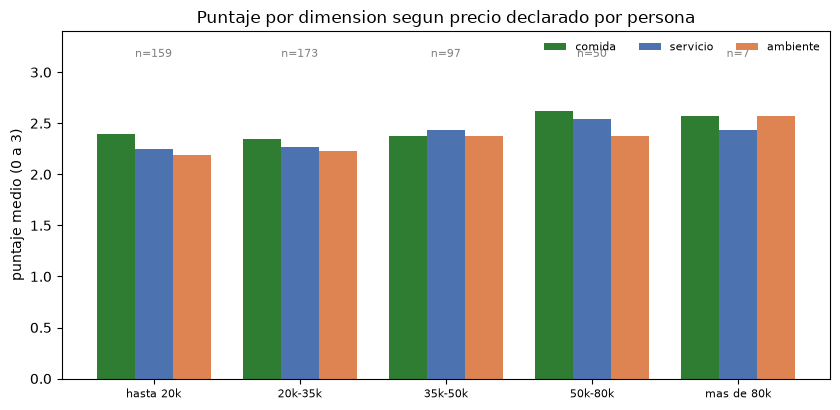

In [28]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(tabla_precio))
ancho = 0.26
for i, (dim, color) in enumerate([('comida', '#2E7D32'), ('servicio', '#4C72B0'), ('ambiente', '#DD8452')]):
    ax.bar(x + (i - 1) * ancho, tabla_precio[dim], width=ancho, label=dim, color=color)
ax.set_xticks(x)
ax.set_xticklabels(tabla_precio.index, fontsize=8)
ax.set_ylabel('puntaje medio (0 a 3)')
ax.set_ylim(0, 3.4)
ax.set_title('Puntaje por dimension segun precio declarado por persona')
ax.legend(ncol=3, fontsize=8, frameon=False)
for i, v in enumerate(tabla_precio['resenas']):
    ax.text(i, 3.15, f'n={int(v)}', ha='center', fontsize=8, color='grey')
plt.tight_layout()
plt.savefig('../images/06_precio_vs_puntaje.png', dpi=150, bbox_inches='tight')
plt.show()


In [29]:
# Sentimiento recalculado SIN las palabras de precio (si no, "caro" ya es negativo por construcción).
sent_sin_precio = pd.Series(sentimiento(con_texto['texto'].map(lambda t: polaridad(t, TEMAS['precio']))),
                            index=con_texto.index)
print('=== Mención de precio según sentimiento (léxico sin palabras de precio) ===')
for s in ['positiva', 'negativa']:
    sub = con_texto[sent_sin_precio == s]
    print(f'  {s:9s} n={len(sub):4d} | menciona precio: {sub["t_precio"].mean() * 100:5.1f}%')
print('  p =', round(p_dos_proporciones(con_texto.loc[sent_sin_precio == 'negativa', 't_precio'],
                                        con_texto.loc[sent_sin_precio == 'positiva', 't_precio']), 3))
print()
print('=== Mención de precio por grupo de puntaje ===')
for g in ['bajo', 'medio', 'alto']:
    sub = con_texto[con_texto['grupo'] == g]
    print(f'  {g:6s} n={len(sub):4d} | menciona precio: {sub["t_precio"].mean() * 100:5.1f}%')
print('  bajo vs alto: p =', round(p_dos_proporciones(bajo['t_precio'], alto['t_precio']), 3))
print()
print('=== Mención de precio por zona ===')
print((con_texto.groupby('zona', observed=True)['t_precio'].agg(['mean', 'size'])
       .assign(mean=lambda d: (d['mean'] * 100).round(1))
       .rename(columns={'mean': 'pct_menciona_precio', 'size': 'resenas'})
       .sort_values('pct_menciona_precio', ascending=False)).to_string())

=== Mención de precio según sentimiento (léxico sin palabras de precio) ===
  positiva  n= 662 | menciona precio:  18.6%
  negativa  n=  32 | menciona precio:  18.8%
  p = 0.981

=== Mención de precio por grupo de puntaje ===
  bajo   n= 419 | menciona precio:  18.4%
  medio  n= 281 | menciona precio:  20.3%
  alto   n= 248 | menciona precio:  15.7%
  bajo vs alto: p = 0.383

=== Mención de precio por zona ===
        pct_menciona_precio  resenas
zona                                
Norte                  19.1      465
Sur                    18.2       66
Oeste                  17.5      189
Centro                 17.3      208


In [30]:
# Chequeo de sesgo: quien declara precio, puntua distinto?
# Si las resenas con precio fueran mas quejonas, la comparacion estaria sesgada.
resenas['tiene_precio'] = resenas['precio'].notna()
print('puntaje promedio segun declare o no el precio:')
print(resenas.groupby('tiene_precio')['score'].agg(['mean', 'size']).round(2).to_string())
print()
print('Si el puntaje es parecido en los dos grupos, la submuestra con precio no')
print('esta sesgada hacia la queja y sirve para comparar niveles de precio.')


puntaje promedio segun declare o no el precio:
              mean  size
tiene_precio            
False         2.20   578
True          2.32   497

Si el puntaje es parecido en los dos grupos, la submuestra con precio no
esta sesgada hacia la queja y sirve para comparar niveles de precio.


## 8. La segunda mirada: reseñas contra la oferta instalada

El punto 1 construyó un proxy de poder adquisitivo con dos medidas internas del dataset del GCBA: `share_alto` (cocinas de ticket alto) y `share_prem` (ambientación premium). Ese proxy se validó contra sí mismo (r ≈ 0,78) y contra el ranking de barrios de mayor poder adquisitivo. **Nunca se validó contra un precio real**, porque el dataset del GCBA no trae precios.

Acá sí hay precios: el precio promedio por persona que declara cada reseña. Entonces se puede hacer la validación que faltaba.

Si `share_alto` (proxy del punto 1) correlaciona con el precio mediano de las reseñas (dato real del punto 3), el proxy queda validado con una fuente independiente. Si no correlaciona, hay que decirlo y corregir el punto 1.

Es el cruce más valioso de todo el trabajo: **dos fuentes distintas, dos métodos distintos, misma conclusión o no.**


In [31]:
locales_p1 = pd.read_csv(PROC / 'establecimientos_clean.csv')

COCINA_ALTO = {'DE AUTOR', 'GOURMET', 'FUSION', 'CONTEMPORANEA', 'FRANCESA', 'TAPAS', 'MARISCOS',
               'PATAGONICA', 'TAILANDESA', 'MEDITERRANEA', 'SUSHI', 'JAPONESA'}
AMBIENTE_PREM = {'ELEGANTE', 'DISEÑO', 'MINIMALISTA', 'VANGUARDISTA', 'ART- DECO', 'ART DECO',
                 'ROMANTICO', 'LITERARIO'}

locales_p1['alto'] = locales_p1['cocina'].str.upper().str.strip().isin(COCINA_ALTO)
locales_p1['prem'] = locales_p1['ambientacion'].str.upper().str.strip().isin(AMBIENTE_PREM)

p1 = locales_p1.groupby('barrio').agg(
    locales=('id', 'size'), alto=('alto', 'sum'), prem=('prem', 'sum'),
    salud=('es_saludable_amplio', 'sum'),
)
p1['share_alto'] = (p1['alto'] / p1['locales'] * 100).round(1)
p1['share_prem'] = (p1['prem'] / p1['locales'] * 100).round(1)
p1['share_salud'] = (p1['salud'] / p1['locales'] * 100).round(1)

p3 = resenas.groupby('barrio').agg(
    resenas=('review_id', 'size'),
    puntaje=('score', 'mean'),
    n_precio=('precio', 'count'),
    precio_mediano=('precio', 'median'),
    precio_medio=('precio', 'mean'),
    precio_p75=('precio', lambda s: s.quantile(0.75)),
    pct_precio_alto=('precio', lambda s: (s >= 40000).mean() * 100),
)

cruce = p1.join(p3, how='inner')
# Dos umbrales: 5 resenas para que el puntaje no sea de una sola persona,
# y 5 precios declarados para que la medida de precio no sea anecdotica.
cruce = cruce[(cruce['resenas'] >= 5) & (cruce['n_precio'] >= 5)]
print('barrios con >= 5 resenas y >= 5 precios:', len(cruce), 'de 48')
print()
print(cruce[['locales', 'share_alto', 'share_prem', 'share_salud', 'resenas', 'n_precio',
             'precio_mediano', 'precio_medio', 'precio_p75', 'puntaje']]
      .sort_values('precio_p75', ascending=False).round(1).to_string())


barrios con >= 5 resenas y >= 5 precios: 20 de 48

               locales  share_alto  share_prem  share_salud  resenas  n_precio  precio_mediano  precio_medio  precio_p75  puntaje
barrio                                                                                                                           
Colegiales          40         5.0         0.0          7.5       32        14         27500.0       33750.0     52500.0      2.3
Puerto Madero       48        20.8        10.4         12.5       23         8         33500.0       40737.5     52225.0      1.9
Palermo            466        13.1         5.8          7.1      169        86         35000.0       37235.4     50000.0      2.3
Belgrano            71         5.6         1.4          2.8       79        40         30000.0       33925.5     45000.0      2.4
Liniers             20         0.0         0.0          0.0        8         6         37500.0       38666.7     43750.0      2.1
Núñez               28         7.1     

In [32]:
def spearman(a, b):
    """Spearman a mano: correlacion de Pearson sobre los rangos."""
    par = pd.concat([a, b], axis=1).dropna()
    return par.iloc[:, 0].rank().corr(par.iloc[:, 1].rank())


MEDIDAS_PRECIO = ['precio_mediano', 'precio_medio', 'precio_p75', 'pct_precio_alto']

print('=== Validacion del proxy del punto 1 contra precios reales ===')
print('n barrios:', len(cruce))
print()
print(f'{"proxy":13s} {"medida de precio":18s} {"Pearson":>8s} {"Spearman":>9s}')
print('-' * 52)
for proxy in ['share_alto', 'share_prem', 'share_salud']:
    for medida in MEDIDAS_PRECIO:
        print(f'{proxy:13s} {medida:18s} {cruce[proxy].corr(cruce[medida]):+8.3f} '
              f'{spearman(cruce[proxy], cruce[medida]):+9.3f}')
    print()


=== Validacion del proxy del punto 1 contra precios reales ===
n barrios: 20

proxy         medida de precio    Pearson  Spearman
----------------------------------------------------
share_alto    precio_mediano       +0.399    +0.377
share_alto    precio_medio         +0.512    +0.486


share_alto    precio_p75           +0.455    +0.439
share_alto    pct_precio_alto      -0.068    -0.005

share_prem    precio_mediano       -0.198    -0.162
share_prem    precio_medio         -0.190    -0.103
share_prem    precio_p75           -0.129    -0.162
share_prem    pct_precio_alto      -0.129    -0.183

share_salud   precio_mediano       +0.430    +0.378


share_salud   precio_medio         +0.542    +0.487
share_salud   precio_p75           +0.541    +0.465
share_salud   pct_precio_alto      -0.041    +0.049



### Cómo leer esta tabla (y por qué no alcanza con un número)

Se probaron **tres proxies del punto 1** (`share_alto`, `share_prem`, `share_salud`) contra **cuatro medidas de precio** del punto 3 (mediana, media, percentil 75 y porcentaje de precios altos). Es a propósito: si el hallazgo dependiera de una sola combinación, sería un artefacto de esa elección.

Lo que se ve:

- `share_alto` y `share_salud` correlacionan **positivo y moderado** con la mediana, la media y el percentil 75 de los precios declarados (r entre 0,40 y 0,54). La señal que el punto 1 esperaba aparece.
- Contra el **porcentaje de precios altos** (≥ $40.000), en cambio, la correlación es cero. Es decir: los barrios con más oferta saludable tienen precios más altos en el medio y en el tramo alto de la distribución, pero no una mayor proporción de reseñas con precio de $40.000 o más.
- `share_prem` (ambientación premium) va en contra: correlación negativa o nula. Ese proxy no se sostiene.

**Veredicto honesto:** el proxy del punto 1 queda **parcialmente validado**. La dirección es la esperada y se repite en tres de las cuatro medidas de precio, pero no es una validación limpia: con 20 barrios el intervalo de confianza es ancho, y el proxy de ambientación falla. Se informa como **señal moderada**, no como confirmación.

Esto no invalida el punto 1: el punto 1 describía estructura de la oferta, no niveles de precio. Lo que agrega el punto 3 es que **la relación entre oferta saludable y precios altos existe en el nivel de precios, pero no en la proporción de reseñas caras**, y que el proxy de ambientación no sirve para estimar poder adquisitivo.


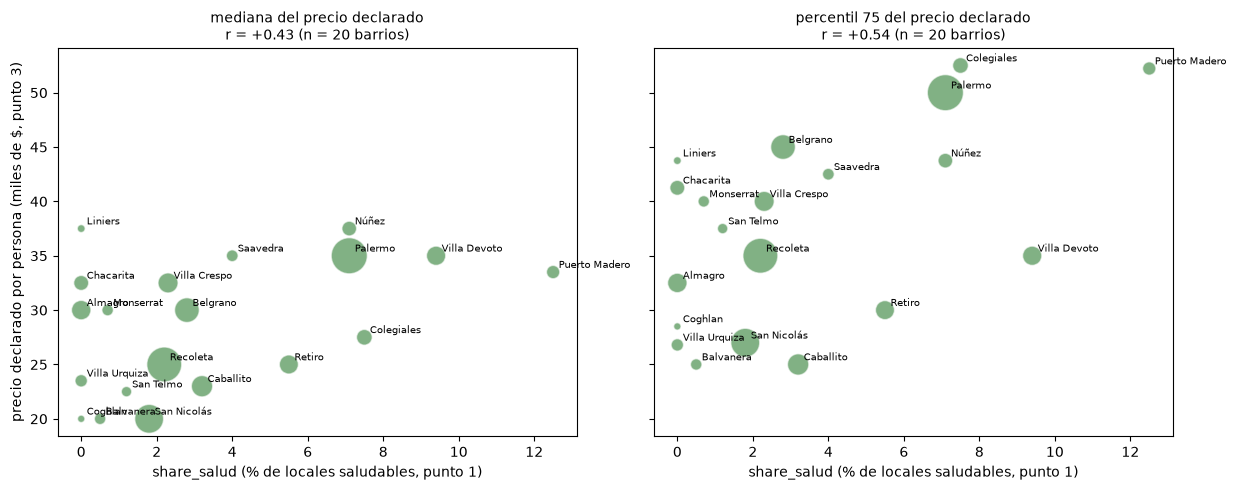

In [33]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(12.5, 5), sharey=True)

for ax, medida, titulo in [
    (ejes[0], 'precio_mediano', 'mediana del precio declarado'),
    (ejes[1], 'precio_p75', 'percentil 75 del precio declarado'),
]:
    ax.scatter(cruce['share_salud'], cruce[medida] / 1000,
               s=cruce['resenas'] * 4, alpha=0.6, color='#2E7D32', edgecolor='white')
    for barrio, fila in cruce.iterrows():
        ax.annotate(barrio, (fila['share_salud'], fila[medida] / 1000),
                    fontsize=7, xytext=(4, 3), textcoords='offset points')
    r = cruce['share_salud'].corr(cruce[medida])
    ax.set_xlabel('share_salud (% de locales saludables, punto 1)')
    ax.set_title(f'{titulo}\nr = {r:+.2f} (n = {len(cruce)} barrios)', fontsize=10)

ejes[0].set_ylabel('precio declarado por persona (miles de $, punto 3)')
plt.tight_layout()
plt.savefig('../images/07_validacion_proxy.png', dpi=150, bbox_inches='tight')
plt.show()


### 8.2 ¿Las dos fuentes ven el mismo mercado?

El dataset del punto 1 lo publica el **Ente de Turismo de la Ciudad** (categoría "Cultura y Turismo" del portal de datos abiertos), no un censo de toda la gastronomía. Guía Óleo es otra foto del mismo mercado. Si las dos reparten los locales parecido entre zonas, la "concentración" del punto 1 es del mercado. Si no, depende de qué registra cada fuente.

In [34]:
dist_p1 = locales_p1['zona'].value_counts(normalize=True).mul(100)
dist_go = dentro['zona'].value_counts(normalize=True).mul(100)
cobertura = pd.DataFrame({'GCBA / Turismo (punto 1)': dist_p1, 'Guía Óleo (punto 3)': dist_go}).round(1)
cobertura['diferencia'] = (cobertura['Guía Óleo (punto 3)'] - cobertura['GCBA / Turismo (punto 1)']).round(1)

print('locales:', len(locales_p1), 'en el GCBA |', len(dentro), 'en Guía Óleo (dentro de CABA)')
for nombre, serie in [('GCBA', locales_p1['barrio']), ('Guía Óleo', dentro['barrio'])]:
    vc = serie.value_counts()
    print(f'{nombre:10s} top 5 barrios = {vc.head(5).sum() / vc.sum() * 100:.0f}% de los locales -> {list(vc.head(5).index)}')
cobertura.loc[['Centro', 'Norte', 'Oeste', 'Sur']]

locales: 2811 en el GCBA | 2235 en Guía Óleo (dentro de CABA)
GCBA       top 5 barrios = 57% de los locales -> ['Palermo', 'San Nicolás', 'Recoleta', 'Balvanera', 'Monserrat']
Guía Óleo  top 5 barrios = 53% de los locales -> ['Palermo', 'Recoleta', 'Villa Devoto', 'Belgrano', 'Caballito']


,GCBA / Turismo (punto 1),Guía Óleo (punto 3),diferencia
zona,,,
Centro,38.8,18.4,-20.4
Norte,35.5,46.8,11.3
Oeste,12.8,26.7,13.9
Sur,12.9,8.1,-4.8


**Lectura:** las dos fuentes **no** ven el mismo mercado. El Centro pesa 39% en el registro de Turismo y 18% en Guía Óleo; el Oeste, al revés, 13% contra 27%. De los cinco barrios con más locales, coinciden solo dos (Palermo y Recoleta): en el GCBA completan San Nicolás, Balvanera y Monserrat (centro turístico y de oficinas) y en Guía Óleo, Villa Devoto, Belgrano y Caballito (residenciales).

**Para el punto 1:** "la oferta está concentrada en el centro" depende de la fuente. Ninguna de las dos es un censo: Turismo registra lo que le interesa al turismo y Guía Óleo lo que tiene visibilidad en la guía. Las conclusiones geográficas tienen que hablar de **oferta registrada**, y las más sólidas son las que se repiten en las dos fuentes (el peso de Palermo y Recoleta, y el Sur siempre chico).

## 9. Hallazgos

Cada hallazgo va en formato de negocio, con las explicaciones alternativas que se evaluaron y qué pasó con cada una.

### Hallazgo 1 — Lo que más castiga una reseña es la espera

**Qué dice el dato:** la comida es la dimensión mejor puntuada (2,35 sobre 3, 48% "Excelente"); servicio (2,21) y ambiente (2,20) quedan abajo. En el texto, el único tema que separa con firmeza las reseñas peor puntuadas de las mejores es **la espera**: aparece en 8,1% de las de puntaje bajo contra 2,4% de las de puntaje alto (p = 0,003). Con el corte estricto (alguna dimensión en "Bueno" o menos) la diferencia crece: 13,2% contra 2,4%. La atención va al revés: se menciona más en las reseñas buenas (41,9% contra 29,8%), o sea, se nombra para elogiar.

**Por qué importa:** si EcoFood vende en un local propio o a través de cafés y restaurantes, la velocidad de servicio es donde se pierde la buena reseña, no el producto. Si vende en góndola, este hallazgo pesa poco.

**Alternativas evaluadas:**

- *Efecto techo* (todos ponen "Excelente" a la comida por defecto). **Descartada:** las tres dimensiones usan toda la escala.
- *Las reseñas peor puntuadas son más largas y por eso mencionan más temas.* **Descartada:** el largo es casi igual (47 contra 44 palabras).
- *El tema estaba inflado por el diccionario.* **Corregido:** "rápido", que casi siempre es un elogio, se contaba como espera y casi duplicaba la brecha. Se separó y el hallazgo sobrevive, con números más chicos.

### Hallazgo 2 — Entre quienes ya consumen, el precio no predice la satisfacción

**Qué dice el dato:** la correlación entre precio declarado y puntaje es casi nula (r = 0,12; con comida r = 0,06). El precio se menciona parecido en reseñas buenas y malas: 18,4% contra 15,7% (p = 0,38), y 18,6% contra 18,8% con el léxico de sentimiento (p = 0,98).

**Por qué importa:** para quien ya eligió el local, pagar más no se traduce en peor reseña. Un producto premium no se castiga por caro **una vez que el cliente lo compró**.

**Lo que este hallazgo NO dice:** no dice que el precio no sea una barrera de entrada. Quien no compra porque le parece caro no va al local y no escribe la reseña (sesgo de supervivencia). Para la pregunta del brief, *¿el precio es una barrera para adoptar productos sostenibles?*, estas reseñas no alcanzan: haría falta preguntarle a quien no compra (encuesta) o relevar precios de góndola.

**Alternativas evaluadas:**

- *Quienes declaran precio son más quejosos.* **Descartada:** puntúan algo más alto (2,32 contra 2,20).
- *En la versión anterior, el precio aparecía mucho más en las reseñas negativas (42,9% contra 20,0%).* **Era un artefacto:** el diccionario contaba "tener en cuenta" como precio y el léxico negativo incluía "caro", así que una reseña con "caro" ya era negativa por construcción. Corregido, la diferencia desaparece.
- *Sesgo de supervivencia.* **No descartada:** es el límite principal de este hallazgo.

### Hallazgo 3 — Lo saludable que la gente busca y menciona es sin TACC

**Qué dice el dato:** 4,1% de las reseñas menciona algo saludable (9,2% con un léxico ampliado), contra una oferta saludable de entre 0,4% y 2,85% de los locales según el punto 1. Para un sitio de gastronomía general, no es poco. Dentro de esas menciones, el subtema más grande es la celiaquía (20 de 39), y 6 de esas 20 usan lenguaje de escasez ("de esos pocos refugios", "un oasis", "no se consigue en todos lados"). La búsqueda dice lo mismo: "sin TACC" tiene 73,5 de interés medio en Google Trends contra 3,9 de "alimentación saludable". Y la oferta especializada es mínima: 13 de 2.235 locales de Guía Óleo (0,6%); el registro del GCBA ni siquiera tiene la categoría.

**Por qué importa:** es el cruce que pide el bonus del caso (alta búsqueda, baja oferta instalada) y apunta a **producto**, no a restaurante: varias reseñas hablan de panificados, almacén y opciones para llevar. Es la oportunidad más concreta del análisis para una línea de productos.

**Alternativas evaluadas:**

- *"Lo saludable casi no se habla, así que no vende."* **Descartada:** era la lectura de la versión anterior y no tenía vara. Contra la oferta que existe, la mención no es baja.
- *"sin TACC" se busca más porque es el rótulo oficial de los envases, no por más interés.* **No descartada del todo,** pero refuerza la lectura de producto: es la palabra con la que la gente busca qué comprar.
- *Son pocas reseñas y podrían ser de pocas personas.* **No descartada:** el scraper no identifica autores. Es una pista fuerte para validar, no una medición del tamaño del mercado.

### Hallazgo 4 — Oferta saludable y precios altos: validación parcial

**Qué dice el dato:** al cruzar los barrios con muestra suficiente (n = 20), `share_salud` del punto 1 correlaciona positivo y moderado con la mediana (r = 0,43), la media (r = 0,54) y el percentil 75 (r = 0,54) del precio declarado. `share_alto` se comporta parecido (0,40 / 0,51 / 0,46). Pero ninguno de los dos correlaciona con el **porcentaje de reseñas con precio de $40.000 o más** (r ≈ 0), y `share_prem` va en contra (r negativo).

**Por qué importa:** el proxy del punto 1 **queda parcialmente validado**: la oferta saludable se instala donde el nivel de precios es más alto.

**Alternativa evaluada:** los precios declarados son ruidosos (números redondos, pocos por barrio). **No descartada:** con 20 barrios el intervalo de confianza es ancho. Además, las dos fuentes no cubren el mismo mercado (sección 8.2).

## 10. Limitaciones

1. **La muestra es de quien escribe reseñas.** No es el público general: es un subconjunto autoseleccionado, con más motivación para opinar (bien o mal) que el cliente promedio.
2. **Guía Óleo no es el universo de locales.** Cubre locales con cierta visibilidad, y reparte la oferta entre zonas muy distinto que el registro de Turismo del punto 1 (sección 8.2).
3. **Es una comunidad chica y nueva.** Se bajó el 98,9% de las reseñas que el sitio declara para CABA (el tope de reseñas visibles solo recorta 7 locales), pero son 1.075 reseñas, todas del último año.
4. **No se sabe cuántas personas distintas escribieron.** El scraper no identifica al autor. Si pocos usuarios escriben mucho, sus gustos pesan de más.
5. **Sesgo de supervivencia en el precio.** Las reseñas son de quien ya compró: no pueden medir si el precio frena a quien no compra.
6. **El léxico de sentimiento es una regla, no un modelo.** Puede fallar con ironía, sarcasmo y negaciones ("no es caro"). Se validó contra los puntajes y, al cruzarlo con un tema, se recalcula sin las palabras de ese tema para no ser circular.
7. **Los temas se miden con un diccionario,** ajustado leyendo el contexto de cada palabra dudosa. Puede seguir habiendo falsos positivos y negativos.
8. **El precio es un bucket declarado por el usuario**, no el ticket real. Lo informa el 45% de las reseñas.
9. **El sentimiento no mide adopción de productos sostenibles.** Mide percepción de la experiencia gastronómica. Para lo primero haría falta preguntar por el producto, no por el local.
10. **Diez reseñas no tienen fecha visible** y quedan como `NaT`. No afecta el análisis porque no se estudia la evolución temporal.

## 11. Qué le sirve al equipo

- **Punto 1:** (a) el proxy de poder adquisitivo queda parcialmente validado: el de cocina sí, el de ambientación premium no. (b) Las dos fuentes reparten la oferta muy distinto (Centro 39% en el GCBA contra 18% en Guía Óleo): las conclusiones geográficas tienen que hablar de "oferta registrada por Turismo" y apoyarse en lo que se repite en las dos. (c) El "cero sin TACC" del punto 1 es un hueco de clasificación del registro, no falta de mercado.
- **Punto 2 (Trends):** "sin TACC" domina la búsqueda y es el subtema saludable que más aparece en las reseñas. Es el cruce más fuerte para el bonus. Ojo: `trends_juntos.csv` se guardó sin la columna de fechas (`index=False`), así que hoy no se puede ver la evolución.
- **Punto 4 (competencia):** la oferta especializada sin TACC existe pero es mínima (13 locales en Guía Óleo, 0,6%, en 9 barrios). Sirve como mapa de competencia directa.
- **Para la presentación**, los mensajes que salen de acá son:
  1. **Sin TACC es la oportunidad más concreta:** búsqueda alta, oferta especializada mínima y consumidores que dicen que cuesta encontrarla.
  2. **La espera es lo que rompe la experiencia** en el punto de venta; la comida no es el problema.
  3. **El precio no castiga a quien ya compra**, pero estos datos no dicen si frena a quien no compra.